<a href="https://colab.research.google.com/github/estefania-mf/NovaRetail/blob/main/S8_Proyecto_Explorando_factores_de_comportamiento_en_NovaRetail%2B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Objetivo del análisis
*NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.*

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("/content/drive/MyDrive/Bootcamp analista de datos/Datasets/datasets_newtrack/novaretail_comportamiento_clientes_2024.csv")
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


**Descripción del conjunto de datos**
El dataset contiene las siguientes columnas:

*   id_cliente — Identificador único del cliente.
*   edad — Edad del cliente.
*   nivel_ingreso — Ingreso anual estimado del cliente.
*   visitas_mes — Número de visitas a la aplicación o sitio web durante el mes.
*   compras_mes — Número de compras realizadas en el mes.
*   gasto_publicidad_dirigida — Gasto en anuncios asignado al usuario.
*   satisfaccion — Calificación de satisfacción del cliente en una escala del 1 al 5.
*   miembro_premium — Indica si el cliente tiene suscripción premium (1) o no (0).
*   abandono — Indica si el cliente abandonó la plataforma (1) o no (0).
*   tipo_dispositivo — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
*   region — Región geográfica del cliente (norte, sur, oeste o este).
*   ingreso_anual — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es **ingreso_anual,** utilizada para **evaluar el impacto económico de los clientes.**

# **Preparar datos**
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
La mayoría de estas variables presentan tipos de datos adecuados.  
La columna `edad` está en dato numérico decimal, es recomendable explorarla, para asegurar que todas las edades estén en número entero, y así evitar edades decimales como 35.5 años de edad.

**Variables binarias**  
Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.}

**Variables categóricas**

Estas variables están correctamente definidas y no requieren transformación adicional.

In [ ]:
# 1)¿Los decimales en edad son distintos 0.0?
tiene_decimales = (df["edad"].dropna() % 1 != 0).any()
print("¿Los datos en la columna edad, tienen decimales distintos a 0.0?:", tiene_decimales)   # True o False
print()

# 2) Corregir el tipo de dato, de decimal a entero
df["edad"] = df["edad"].astype("int64")
print("Verificar la conversión del tipo de dato en ´edad´ de float64 a int64:")
print(df.dtypes)

¿Los datos en la columna edad, tienen decimales distintos a 0.0?: False

Verificar la conversión del tipo de dato en ´edad´ de float64 a int64:
id_cliente                    object
edad                           int64
nivel_ingreso                float64
visitas_mes                    int64
compras_mes                    int64
gasto_publicidad_dirigida    float64
satisfaccion                 float64
miembro_premium                int64
abandono                       int64
tipo_dispositivo              object
region                        object
ingreso_anual                float64
dtype: object


### **Explorar variables numéricas**

In [ ]:
# Estadísticas descriptivas de variables numéricas
columnas_numericas = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes', 'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']

print("Resumen estadística descriptiva para variables numéricas")
print()
print(df[columnas_numericas].describe())

Resumen estadística descriptiva para variables numéricas

               edad  nivel_ingreso   visitas_mes   compras_mes  \
count  15000.000000   15000.000000  15000.000000  15000.000000   
mean      38.262400   30019.704782     10.029000      1.206467   
std       11.492378    9833.166305      3.158189      1.105284   
min       18.000000    8000.000000      1.000000      0.000000   
25%       30.000000   23127.097500      8.000000      0.000000   
50%       38.000000   30023.745000     10.000000      1.000000   
75%       46.000000   36768.440000     12.000000      2.000000   
max       75.000000   74790.840000     25.000000      8.000000   

       gasto_publicidad_dirigida  satisfaccion  ingreso_anual  
count               15000.000000  15000.000000   15000.000000  
mean                   20.149301      3.603693      36.594180  
std                    10.880724      0.685300      34.484888  
min                     0.000000      1.000000       0.000000  
25%                    12.3

Diagnóstico inicial de variables numéricas

- edad: distribución equilibrada. La media (38.26) y la mediana (38) son prácticamente iguales, lo que indica simetría, y el rango de 18 a 75 años es coherente para clientes adultos, sin valores imposibles.
- nivel_ingreso: también simétrica (media y mediana ≈ 30,000), pero el máximo de 74,790.84 está demasiado distante del 75% de los datos, lo que puede señalar posibles outliers en la parte alta.
- visitas_mes: muy concentrada en torno a 10 visitas (media y mediana iguales, 50 % de los clientes entre 8 y 12). El máximo de 25 queda bastante alejado del 75% de losd atos.
- compras_mes: al menos el 25 % de los clientes no compró nada en el mes (Q1 = 0). La mediana es 1 compra y el máximo 8, así que la distribución está sesgada a la derecha: pocos clientes compran mucho.
- gasto_publicidad_dirigida: el centro es estable (media ≈ mediana ≈ 20), pero el máximo de 75.51 supera con holgura el límite de outliers. También hay clientes con gasto de 0, que conviene explorar.
- satisfaccion: escala de 1 a 5 con promedio de 3.6 y poca dispersión (std 0.69). Un detalle clave: tiene decimales (3.1, 4.1), así que no es una escala Likert de enteros.
- ingreso_anual: es la variable más llamativa. Al menos el 25 % tiene valor 0, la media (36.6) supera a la mediana (30.7) y la desviación estándar es casi igual a la media: fuerte sesgo a la derecha con un máximo de 244.69. Al medir ingreso que el cliente genera para la empresa, los ceros coinciden con quienes no compraron.

### **Explorar variables binarias**

In [ ]:
# Verificar que cada columna tenga únicamente dos valores posibles
columnas_binarias = ['miembro_premium', 'abandono']
for col in columnas_binarias:
    print(col, "→", df[col].nunique(), "valores:", df[col].unique())

#Proporción general de cada variable:
for col in ['miembro_premium', 'abandono']:
    resumen = pd.DataFrame({
        "conteo": df[col].value_counts(),
        "porcentaje": (df[col].value_counts(normalize=True) * 100).round(2)
    })
    print(col)
    print(resumen)
    print()

miembro_premium → 2 valores: [0 1]
abandono → 2 valores: [0 1]
miembro_premium
                 conteo  porcentaje
miembro_premium                    
0                 12911       86.07
1                  2089       13.93

abandono
          conteo  porcentaje
abandono                    
0          12739       84.93
1           2261       15.07



Diagnóstico inicial de variables binarias

*   miembro_premium — 13.93 % de los clientes son miembros premium (2,089 de 15,
000), frente a 86.07 % que no lo son.
*   abandono — 15.07 % de los clientes abandonó (2,261 de 15,000). Esa es tu tasa de abandono general.

Queda pendiente responder, ¿cuántos premium abandonan? ¿la tasa de clientes premium que abandonan es mayor o menor que la de los no premium?.

In [ ]:
# Tabla de abandono por grupo (cada fila suma 100 %)
tabla = pd.crosstab(df['miembro_premium'], df['abandono'], normalize='index').mul(100).round(2)

# Etiquetas descriptivas
tabla = tabla.rename(index={0: 'No premium', 1: 'Premium'},
                     columns={0: '% Se queda', 1: '% Abandona'})
tabla = tabla.rename_axis(index='Tipo de cliente', columns=None)

print("Tasa de abandono por tipo de cliente")
print("(Cada fila suma 100 %: porcentaje de clientes de ese grupo que se queda o abandona)")
print()
print(tabla)
print()

# Interpretación automática
tasa_no_premium = tabla.loc['No premium', '% Abandona']
tasa_premium = tabla.loc['Premium', '% Abandona']

print(f"Abandona el {tasa_no_premium}% de los clientes no premium.")
print(f"Abandona el {tasa_premium}% de los clientes premium.")
print(f"Los no premium abandonan {tasa_no_premium / tasa_premium:.1f} veces más que los premium.")

Tasa de abandono por tipo de cliente
(Cada fila suma 100 %: porcentaje de clientes de ese grupo que se queda o abandona)

                 % Se queda  % Abandona
Tipo de cliente                        
No premium            83.19       16.81
Premium               95.64        4.36

Abandona el 16.81% de los clientes no premium.
Abandona el 4.36% de los clientes premium.
Los no premium abandonan 3.9 veces más que los premium.


### **Explorar variables categóricas**

In [ ]:
# Verificar el número de valores únicos por variable categórica
columnas_categoricas = ['tipo_dispositivo', 'region']
print(df[columnas_categoricas].describe())


       tipo_dispositivo region
count             15000  15000
unique                3      4
top               móvil  norte
freq               9818   4395


In [ ]:
# Explorar variables categóricas y cómo se distribuyen
print("Frecuencia absoluta de tipo de dispositivo:")
print(df['tipo_dispositivo'].value_counts())
print()
print("Frecuencia absoluta de region:")
print(df['region'].value_counts())

Frecuencia absoluta de tipo de dispositivo:
tipo_dispositivo
móvil         9818
escritorio    3720
tablet        1462
Name: count, dtype: int64

Frecuencia absoluta de region:
region
norte    4395
oeste    3810
sur      3726
este     3069
Name: count, dtype: int64


Diagnóstico inicial de variables categóricas

*   tipo_dispositivo — El canal está dominado por móvil, con el 65.5 % de los
clientes (9,818), casi dos de cada tres. Escritorio representa el 24.8 % y tablet solo el 9.7 %. Esto sugiere que la experiencia móvil es la más crítica para el negocio, y que cualquier conclusión sobre tablet se basa en un grupo pequeño (1,462 clientes), así que conviene interpretarla con cautela.
*   region — La distribución es relativamente equilibrada: norte concentra la mayor parte (29.3 %) y este la menor (20.5 %), con oeste (25.4 %) y sur (24.8 %) prácticamente empatadas. No hay una región marginal, por lo que las comparaciones entre regiones serán confiables.


Cruzar ambas con abandono para ver si algún dispositivo o región tiene una tasa de abandono por encima del 15.07 % general:

In [ ]:
for col in ['tipo_dispositivo', 'region']:
    print(f"Tasa de abandono por {col}:")
    print(df.groupby(col)['abandono'].mean().mul(100).round(2).sort_values(ascending=False))
    print()

Tasa de abandono por tipo_dispositivo:
tipo_dispositivo
tablet        15.60
escritorio    15.35
móvil         14.89
Name: abandono, dtype: float64

Tasa de abandono por region:
region
oeste    15.75
sur      15.46
este     14.70
norte    14.43
Name: abandono, dtype: float64



Con esto concluimos que ni el tipo de dispositivo ni la región parecen influir de forma relevante en el abandono. Todas las tasas se mueven en un rango muy estrecho, entre 14.4 % y 15.8 %, prácticamente pegadas al 15.07 % general.

Supuestos

* El análisis se realiza utilizando todo el conjunto de datos disponible.
* Los datos no presentan errores y están correctamente tipificados.
* Se utilizan distintos coeficientes según el tipo de variable:
  - Pearson asume relaciones lineales entre variables numéricas.
  - Spearman evalúa relaciones monótonas y no requiere normalidad.
  - Punto biserial se usa para relaciones numérica–binaria.
  - Cramér (V) se usa para asociaciones entre variables categóricas.

Supuesto central:

Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

### **Visualización de relaciones**
Observamos cómo se relacionan las variables numéricas.

## **Heatmap**

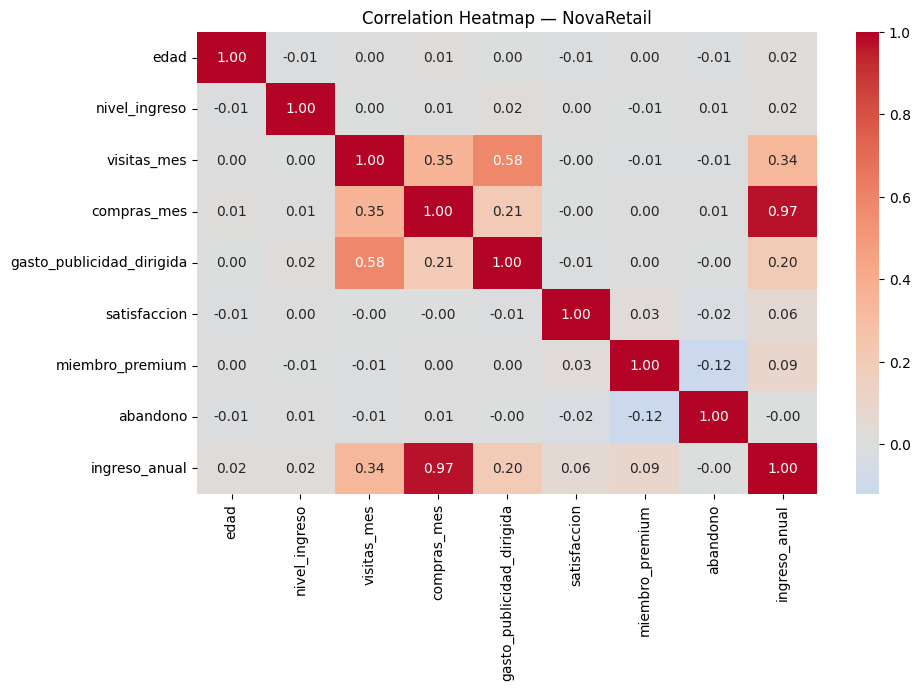

In [ ]:
# Visualizar la matriz de correlación para identificar relaciones
corr = df.select_dtypes(include='number').corr()

plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap — NovaRetail")
plt.show()


Observaciones generales (Heatmap)

* Se observa que la mayoría de las variables son prácticamente independientes entre sí: casi todas las correlaciones están entre −0.02 y 0.03. En particular, edad, nivel_ingreso y satisfaccion no muestran relación lineal con ninguna otra variable.
* La relación más fuerte entre variables de comportamiento es gasto_publicidad_dirigida ↔ visitas_mes (0.58), una correlación moderada: a mayor inversión publicitaria, más visitas. Sin embargo, su relación con compras_mes es débil (0.21), lo que sugiere que la publicidad atrae tráfico pero no se traduce con la misma fuerza en compras.
* visitas_mes y compras_mes tienen una correlación moderada-baja (0.35): visitar más se asocia con comprar más, pero no de forma determinante.
* abandono solo muestra relación con miembro_premium (−0.12), en el sentido esperado: ser premium se asocia con menor abandono.
* Llama la atención que satisfaccion casi no se relaciona con abandono (−0.02). Es un hallazgo contraintuitivo que vale la pena explorar, por ejemplo comparando la satisfacción promedio entre quienes abandonan y quienes no.

Observaciones respecto a ingreso_anual

* Presenta una correlación casi perfecta con compras_mes (0.97), lo que indica que es prácticamente una consecuencia directa del número de compras (probablemente compras × ticket promedio). Sus correlaciones con visitas_mes (0.34) y gasto_publicidad_dirigida (0.20) replican casi exactamente las de compras_mes (0.35 y 0.21), lo que refuerza que su relación con esas variables es indirecta, a través de las compras. Su correlación con nivel_ingreso es prácticamente nula (0.02). Ya que ingreso_anual no mide el ingreso del cliente, sino el ingreso que el cliente genera para la empresa. No se relaciona con abandono (−0.00): los clientes que abandonan no generaban, en promedio, ni más ni menos ingreso. Esto significa que el abandono afecta por igual a clientes de alto y bajo valor, lo cual tiene implicaciones para priorizar estrategias de retención.


## **Scatterplot general**

No es necesario un scatterplot general, no aportaría mucho por tres razones:

* La mayoría de las correlaciones son prácticamente cero. Graficar edad, nivel_ingreso o satisfaccion contra el resto produciría nubes de puntos sin forma, que no añaden información al heatmap.
* Varias variables no son aptas para un scatterplot. miembro_premium y abandono son binarias (los puntos quedarían en dos líneas), y compras_mes y visitas_mes son discretas con pocos valores, lo que genera columnas de puntos superpuestos.
* Con 15,000 registros hay sobreposición severa. Una matriz de 9 × 9 variables serían 81 gráficas saturadas, difíciles de leer y lentas de generar.


Scatterplot para pares clave

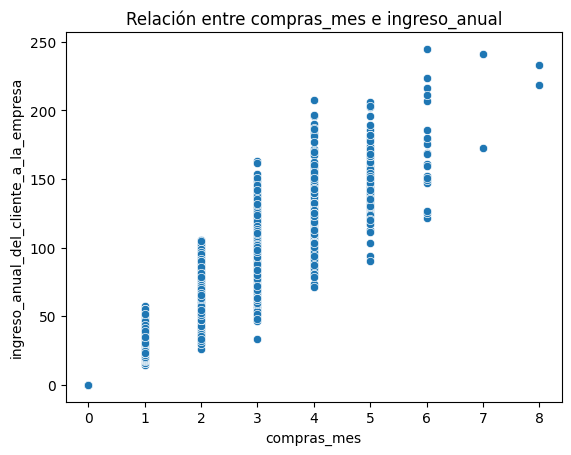

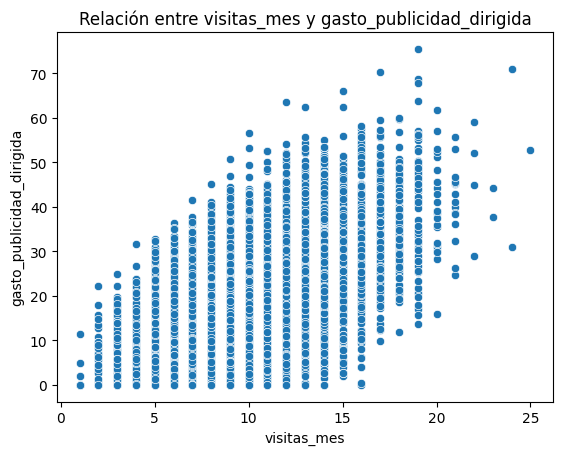

In [ ]:
# Visualizar pares de variables con relaciones moderadas o fuertes

sns.scatterplot(
    data=df,
    x="compras_mes",
    y="ingreso_anual"
)

plt.title("Relación entre compras_mes e ingreso_anual")
plt.xlabel("compras_mes")
plt.ylabel("ingreso_anual_del_cliente_a_la_empresa")
plt.show()

sns.scatterplot(
    data=df,
    x="visitas_mes",
    y="gasto_publicidad_dirigida"
)

plt.title("Relación entre visitas_mes y gasto_publicidad_dirigida")
plt.xlabel("visitas_mes")
plt.ylabel("gasto_publicidad_dirigida")
plt.show()

**Observaciones iniciales (Scatterplot)**

**compras_mes ↔ ingreso_anual (0.97)**

* Dirección: positiva y claramente lineal. Cada compra adicional al mes eleva el ingreso anual en una cantidad bastante constante (aproximadamente 30 unidades por compra), lo que se ve en cómo las columnas de puntos “suben en escalera”.
* Dispersión: baja en términos generales, pero aumenta conforme crecen las compras. Con 1 compra, el ingreso va aproximadamente de 15 a 57; con 4 compras, de 70 a 207. Es decir, los clientes que compran más tienen tickets más variables.
* Outliers: pocos y moderados. Destaca un cliente con 3 compras y un ingreso cercano a 33, por debajo de su grupo. Los clientes con 7 y 8 compras son muy escasos (5 puntos aproximadamente), así que más que outliers son casos poco frecuentes del extremo superior.
Dato relevante: con 0 compras el ingreso es exactamente 0, lo que confirma que el 25 % de ceros en ingreso_anual corresponde a los clientes que no compraron.
* Colinealidad: alta. ingreso_anual parece derivarse casi directamente de compras_mes; ambas variables aportan prácticamente la misma información. En un modelo predictivo convendría conservar solo una.

**visitas_mes ↔ gasto_publicidad_dirigida (0.58)**

* Dirección positiva. A mayor gasto en publicidad dirigida, más visitas al mes.
* Dispersión: alta. Para un mismo número de visitas el gasto varía enormemente; por ejemplo, con 15 visitas hay clientes con gasto cercano a 0 y otros por encima de 60. Además, se observa un patrón en forma de abanico: con pocas visitas el gasto se mantiene bajo, mientras que con muchas visitas el gasto mínimo sube (casi no hay clientes con más de 17 visitas y gasto por debajo de 10).
* Outliers: en el eje del gasto, algunos clientes superan 60 (con un máximo cercano a 75 en 19 visitas), coherentes con los valores extremos detectados en el diagnóstico inicial. En el eje de visitas, los clientes con 22 a 25 visitas son pocos y aislados. También hay un caso atípico con 15 visitas y gasto prácticamente 0.
* Colinealidad: moderada, no problemática. Con r = 0.58, la publicidad explica alrededor de un tercio de la variación en las visitas (r² ≈ 0.34); el resto depende de otros factores. Ambas variables pueden conservarse en un análisis o modelo sin generar redundancia.


## **Coeficientes de correlación y evidencia numérica**
En esta sección, se reportan coeficientes que respaldan los patrones observados visualmente, utilizando el método adecuado según el tipo de variables.

Pearson / Spearman

In [ ]:
# Calcular correlación entre variables relevantes
# Correlación entre compras_mes e ingreso_anual
corr_pearson  = df['compras_mes'].corr(df['ingreso_anual'], method='pearson')
corr_spearman = df['compras_mes'].corr(df['ingreso_anual'], method='spearman')

print(f"Correlacion entre: compras_mes e ingreso_anual")
print(f"Pearson: {corr_pearson:.3f}")
print(f"Spearman: {corr_spearman:.3f}")

Correlacion entre: compras_mes e ingreso_anual
Pearson: 0.967
Spearman: 0.967


In [ ]:
# Calcular correlación entre variables relevantes
# Correlación entre visitas_mes y gasto_publicidad_dirigida
corr_pearson  = df['visitas_mes'].corr(df['gasto_publicidad_dirigida'], method='pearson')
corr_spearman = df['visitas_mes'].corr(df['gasto_publicidad_dirigida'], method='spearman')

print(f"Correlacion entre: compras_mes e ingreso_anual")
print(f"Pearson: {corr_pearson:.3f}")
print(f"Spearman: {corr_spearman:.3f}")


Correlacion entre: compras_mes e ingreso_anual
Pearson: 0.579
Spearman: 0.559


Observaciones de correlación

**compras_mes ↔ ingreso_anual**

* Relación muy fuerte y positiva. Con un coeficiente de 0.967, a más compras al mes, mayor ingreso anual generado para la empresa, de forma muy consistente.
* Pearson y Spearman son idénticos (0.967). Esto indica que la relación es lineal (no solo monótona) y que los pocos valores atípicos que vimos en el scatterplot, como el cliente con 3 compras e ingreso bajo, no distorsionan el resultado.
* Confirma lo observado visualmente. El patrón en escalera del scatterplot y el 0.97 del heatmap quedan respaldados numéricamente.
* Implica colinealidad. Ambas variables aportan prácticamente la misma información, y todo apunta a que ingreso_anual se deriva casi directamente de compras_mes. Para un modelo predictivo conviene conservar solo una de las dos, según el objetivo: compras_mes si interesa el comportamiento del cliente, o ingreso_anual si interesa el valor económico.

“La correlación entre compras_mes e ingreso_anual es muy fuerte y positiva (Pearson = Spearman = 0.967), lo que indica una relación lineal robusta ante valores atípicos. Ambas variables son prácticamente redundantes, por lo que no deberían incluirse juntas en un mismo modelo.”

**visitas_mes ↔ gasto_publicidad_dirigida**

* Relación positiva y moderada. Con valores cercanos a 0.58, a mayor gasto en publicidad dirigida, más visitas al mes, aunque la relación dista de ser perfecta.
* Pearson (0.579) es ligeramente mayor que Spearman (0.559). La diferencia es pequeña (0.02), lo que indica que la relación es esencialmente lineal. El leve exceso de Pearson sugiere que los valores extremos de gasto (los clientes por encima de 60 que vimos en el scatterplot) refuerzan un poco la correlación, pero sin distorsionarla de forma importante.
* Colinealidad moderada, no problemática. Ambas variables aportan información distinta y pueden conservarse juntas en un análisis o modelo.

“La correlación entre visitas_mes y gasto_publicidad_dirigida es positiva y moderada (Pearson = 0.579; Spearman = 0.559). La similitud entre ambos coeficientes indica una relación aproximadamente lineal, levemente influida por valores extremos de gasto. La publicidad explica cerca de un tercio de la variación en las visitas, por lo que contribuye al tráfico, pero no lo determina por sí sola.”

## **Punto-biserial**

In [ ]:
# Calcular correlación entre variables relevantes
from scipy.stats import pointbiserialr

# Correlación punto-biserial entre abandono y compras_mes
binaria, numerica = 'abandono', 'compras_mes'
r_pb, p_valor = pointbiserialr(df[binaria], df[numerica])

print(f"Correlación punto-biserial entre: {binaria} y {numerica}")
print(f"r: {r_pb:.3f}")
print(f"p-valor: {p_valor:.4f}")
print()

# Complemento: comparación de compras por grupo
print(f"{numerica} según {binaria}:")
print(df.groupby(binaria)[numerica].agg(['mean', 'median']).round(2))
print()

# Correlación punto-biserial entre miembro_premium y ingreso_anual
binaria, numerica = 'miembro_premium', 'ingreso_anual'
r_pb, p_valor = pointbiserialr(df[binaria], df[numerica])

print(f"Correlación punto-biserial entre: {binaria} y {numerica}")
print(f"r: {r_pb:.3f}")
print(f"p-valor: {p_valor:.4f}")
print()

# Complemento
print(f"{numerica} según {binaria}:")
print(df.groupby(binaria)[numerica].agg(['mean', 'median']).round(2))


Correlación punto-biserial entre: abandono y compras_mes
r: 0.008
p-valor: 0.3099

compras_mes según abandono:
          mean  median
abandono              
0         1.20     1.0
1         1.23     1.0

Correlación punto-biserial entre: miembro_premium y ingreso_anual
r: 0.093
p-valor: 0.0000

ingreso_anual según miembro_premium:
                  mean  median
miembro_premium               
0                35.30   29.95
1                44.58   37.70


Observaciones Punto-biserial

**abandono vs compras_mes**
- No hay relación. El coeficiente (r = 0.008) es prácticamente cero, lo que confirma lo que mostraba el heatmap.
- No es estadísticamente significativa. Con un p-valor de 0.31 (mayor a 0.05), la mínima diferencia observada es compatible con el azar.
- Las medias y medianas lo confirman. Quienes se quedan compran en promedio 1.20 veces al mes y quienes abandonan 1.23; ambos grupos tienen una mediana de 1 compra. En la práctica, los dos grupos compran igual.
- Implicación para el negocio: los clientes que abandonan no compraban menos antes de irse. El volumen de compras no funciona como señal de alerta temprana del abandono, así que las estrategias de retención deberían apoyarse en otros indicadores, como la membresía premium, que sí mostró una diferencia clara.

Una precaución al interpretarlo: compras_mes es una foto de un solo periodo. Si el abandono se gesta como una caída progresiva de compras a lo largo de varios meses, estos datos no lo captarían; para eso se necesitaría información histórica por cliente.

**miembro_premium vs ingreso_anual**
- Relación positiva, débil pero estadísticamente significativa. El coeficiente (r = 0.093) es bajo, pero el p-valor indica que la diferencia no se debe al azar. En el reporte conviene escribirlo como p < 0.0001, no como 0.0000.
- La diferencia en dinero sí es relevante. Los clientes premium generan en promedio 44.58 vs. 35.30 (unas 9.3 unidades más) y en mediana 37.70 vs. 29.95. En ambos casos, alrededor de un 26 % más de ingreso que los no premium.
- ¿Por qué el coeficiente es tan bajo si la diferencia es notable? Porque dentro de cada grupo hay mucha variabilidad (la desviación estándar de ingreso_anual es de 34.5) y los premium son solo el 14 % de la base. La membresía explica menos del 1 % de la variación total del ingreso (r² ≈ 0.009), aunque en promedio sí marque una diferencia clara. Es un buen ejemplo de por qué conviene acompañar el coeficiente con medias y medianas.
- Conecta con el hallazgo anterior. Como premium y no premium compran con la misma frecuencia (1.22 vs. 1.20), el mayor ingreso de los premium probablemente proviene de un ticket promedio más alto por compra.
- Implicación para el negocio: los clientes premium no solo abandonan mucho menos (4.36 % vs. 16.81 %), sino que también generan más ingreso. Esto refuerza el valor de convertir clientes a la membresía premium como estrategia de retención y de crecimiento del ingreso.

“La membresía premium muestra una relación positiva débil, pero significativa, con el ingreso anual (r punto-biserial = 0.093; p < 0.0001). Los clientes premium generan en promedio un 26 % más de ingreso que los no premium (media 44.58 vs. 35.30; mediana 37.70 vs. 29.95), pese a comprar con la misma frecuencia, lo que sugiere un mayor gasto por compra.”

## **V de Cramér**

In [ ]:
# Función para calcular V de Cramér
import numpy as np
from scipy.stats import chi2_contingency

def cramer_v(df, col1, col2):
    tabla = pd.crosstab(df[col1], df[col2])
    chi2, p_value, dof, expected = chi2_contingency(tabla)
    n = tabla.values.sum()
    v = np.sqrt(chi2 / (n * (min(tabla.shape) -1)))
    return v

coef_cramer = cramer_v(df, "region", "tipo_dispositivo")

print("\nCorrelación entre: region y tipo dispositivo")
print(f"V de Cramér: {coef_cramer :.3f}")


Correlación entre: region y tipo dispositivo
V de Cramér: 0.012


In [ ]:
# Aplicar V de Cramér en variables relevantes
import numpy as np
from scipy.stats import chi2_contingency

# V de Cramér entre miembro_premium y tipo_dispositivo
x, y = 'miembro_premium', 'tipo_dispositivo'

tabla = pd.crosstab(df[x], df[y])
chi2, p_valor, _, _ = chi2_contingency(tabla, correction=False)
n = tabla.to_numpy().sum()
k = min(tabla.shape) - 1
v_cramer = np.sqrt(chi2 / (n * k))

print(f"V de Cramér entre: {x} y {y}")
print(f"V: {v_cramer:.3f}")
print(f"p-valor: {p_valor:.4f}")
print()

# Complemento: % de clientes premium dentro de cada tipo de dispositivo
print(f"% de clientes premium según {y}:")
print(pd.crosstab(df[y], df[x], normalize='index').mul(100).round(2))
print()

# V de Cramér entre miembro_premium y region
x, y = 'miembro_premium', 'region'

tabla = pd.crosstab(df[x], df[y])
chi2, p_valor, _, _ = chi2_contingency(tabla, correction=False)
n = tabla.to_numpy().sum()
k = min(tabla.shape) - 1
v_cramer = np.sqrt(chi2 / (n * k))

print(f"V de Cramér entre: {x} y {y}")
print(f"V: {v_cramer:.3f}")
print(f"p-valor: {p_valor:.4f}")
print()

# Complemento: % de clientes premium dentro de cada tipo de dispositivo
print(f"% de clientes premium según {y}:")
print(pd.crosstab(df[y], df[x], normalize='index').mul(100).round(2))

V de Cramér entre: miembro_premium y tipo_dispositivo
V: 0.020
p-valor: 0.0540

% de clientes premium según tipo_dispositivo:
miembro_premium       0      1
tipo_dispositivo              
escritorio        87.23  12.77
móvil             85.76  14.24
tablet            85.23  14.77

V de Cramér entre: miembro_premium y region
V: 0.013
p-valor: 0.4989

% de clientes premium según region:
miembro_premium      0      1
region                       
este             86.25  13.75
norte            86.48  13.52
oeste            86.17  13.83
sur              85.35  14.65


### **Observaciones V de Cramér**

**miembro_premium ↔ tipo_dispositivo** No se encontró asociación relevante entre la membresía premium y el tipo de dispositivo (V de Cramér = 0.020; p = 0.054). La proporción de clientes premium es similar en todos los canales (entre 12.77 % y 14.77 %, frente a 13.93 % general), por lo que la membresía no se concentra en ningún dispositivo.

**miembro_premium ↔ region **No se encontró asociación entre la membresía premium y la región (V de Cramér = 0.013; p = 0.50). La proporción de clientes premium es homogénea entre regiones (de 13.52 % a 14.65 %, frente a 13.93 % general), por lo que la membresía se distribuye de forma pareja geográficamente.

# **Interpretación de resultados para el negocio**

**Hallazgo 1 — La membresía premium se asocia con mucho menor abandono**
Evidencia visual: en el heatmap, miembro_premium ↔ abandono es la única celda que destaca en la fila de abandono (−0.12), mientras que el resto de las variables se mantiene prácticamente en cero.

Evidencia numérica: la tasa de abandono es de 16.81 % en no premium vs. 4.36 % en premium, frente a 15.07 % general. Los no premium abandonan casi 4 veces más.

Interpretación de todas las variables analizadas, la membresía premium es la que mejor distingue a quienes se quedan de quienes se van. El coeficiente parece bajo porque Pearson subestima relaciones entre variables binarias; la comparación de tasas muestra que la diferencia es grande.

No podemos afirmar que la membresía cause la retención. Es posible que los clientes que ya eran leales sean quienes eligen hacerse premium. Para establecer causalidad se necesitaría, por ejemplo, observar a los clientes antes y después de adquirir la membresía, o un experimento.

Implicación de negocio convertir clientes a premium es la palanca más prometedora de retención identificada, y vale la pena probarla con campañas de conversión dirigidas a no premium, midiendo su efecto en el abandono.

**Hallazgo 2 — El abandono no se explica por la actividad, la satisfacción, el canal ni la región**
Evidencia visual: en el heatmap, la fila de abandono muestra valores entre −0.02 y 0.01 con todas las variables excepto premium.

Evidencia numérica: Evidencia numérica: compras de 1.23 vs. 1.20 entre quienes abandonan y quienes no (r = 0.008, p = 0.31); satisfacción con r = −0.02; tasas de abandono entre 14.89 % y 15.60 % por dispositivo y entre 14.43 % y 15.75 % por región. Además, la membresía premium se distribuye de forma pareja por dispositivo (V = 0.020) y región (V = 0.013), así que no mezcla esos efectos.

Interpretación con las variables disponibles, los clientes que abandonan son prácticamente indistinguibles de los que se quedan, salvo por la membresía. El abandono también afecta por igual a clientes de alto y bajo valor (correlación de 0.00 con ingreso_anual).

No podemos afirmar que la satisfacción o la actividad sean irrelevantes para el abandono. Los datos son una foto de un solo periodo y no captan tendencias, como una caída progresiva de compras antes de irse, y la satisfacción parece ser un promedio que podría ocultar experiencias negativas puntuales.

Implicación de negocio con estos datos no hay señales de alerta temprana para anticipar el abandono. Conviene recolectar información histórica por cliente (evolución mensual de compras y visitas, contactos con soporte, motivos de baja) para poder construir un modelo predictivo útil.

**Hallazgo 3 — Los premium generan cerca de 26 % más ingreso sin comprar con mayor frecuencia**
Evidencia visual: en el heatmap, miembro_premium tiene una correlación de 0.09 con ingreso_anual, pero 0.00 con compras_mes.

Evidencia numérica: ingreso promedio de 44.58 vs. 35.30 (mediana 37.70 vs. 29.95; r punto-biserial = 0.093, p < 0.0001), con compras prácticamente iguales: 1.22 vs. 1.20 al mes (r = 0.003, p = 0.67).

Interpretación: como ambos grupos compran con la misma frecuencia, el mayor ingreso de los premium probablemente proviene de un gasto más alto por compra.

No podemos afirmar: que el ticket promedio sea mayor hasta calcular directamente el ingreso por compra, ni que la membresía provoque ese mayor gasto. Además, la membresía explica menos del 1 % de la variación total del ingreso, así que hay mucha variabilidad dentro de cada grupo.

Implicación de negocio: los premium son más leales y más valiosos, lo que fortalece el caso de inversión en la membresía. Su valor está en el monto por compra y la permanencia, no en la frecuencia.

**Hallazgo 4 — La publicidad dirigida atrae visitas, pero se traduce débilmente en compras**
Evidencia visual: el scatterplot de publicidad vs. visitas muestra una tendencia positiva con alta dispersión; en el heatmap, la relación con compras es mucho más débil.

Evidencia numérica: publicidad ↔ visitas con Pearson = 0.579 y Spearman = 0.559 (r² ≈ 0.34), frente a publicidad ↔ compras de solo 0.21.

Interpretación: la publicidad se asocia con más tráfico, pero buena parte de ese tráfico no termina en compra. La relación es aproximadamente lineal, sin señales claras de rendimientos decrecientes.

No podemos afirmar: que la publicidad cause las visitas. También es posible que la publicidad dirigida se asigne a clientes que ya visitan mucho, lo que invertiría la dirección de la relación.

Implicación de negocio: el cuello de botella parece estar en la conversión de visitas a compras, no en la atracción de tráfico. Antes de aumentar el presupuesto publicitario, convendría revisar la experiencia de compra y la efectividad de las campañas en términos de ventas, no solo de visitas.



# **Limitaciones y próximos pasos**
Limitaciones
Correlación ≠ causalidad. Las relaciones encontradas (por ejemplo, premium y menor abandono, o publicidad y visitas) indican asociación, no que una variable provoque la otra.
Datos de un solo periodo. El dataset es una foto en el tiempo, por lo que no permite observar tendencias, como una caída progresiva de compras o visitas antes del abandono.
Posible sesgo de autoselección en premium. Los clientes que eligen la membresía podrían ser, desde antes, más leales o de mayor valor, lo que impide atribuir la retención a la membresía en sí.

**Próximos pasos**
**Paso 1. Probar segmentación adicional**

* Premium × satisfacción: analizar si la satisfacción sí influye en el abandono dentro de cada grupo (premium y no premium), ya que el efecto podría estar oculto en el total.
* Grupos de edad y niveles de ingreso del cliente: agrupar edad y nivel_ingreso en rangos y comparar tasas de abandono, para detectar relaciones no lineales que la correlación no captura.
* Clientes sin compras: estudiar al 25 % de clientes con 0 compras en el mes (actividad, satisfacción, membresía) como posible segmento en riesgo.
* Clientes de alto valor: segmentar por cuartiles de ingreso_anual para priorizar estrategias de retención en quienes más ingreso generan.

**Paso 2. Validar las hipótesis sobre la membresía premium**
* Calcular el ingreso por compra para confirmar si los premium tienen un ticket promedio más alto. -Diseñar una prueba piloto de conversión a premium con un grupo de control, para medir si la membresía reduce el abandono de forma causal.

**Paso 3. Fortalecer los datos y preparar un modelo predictivo de abandono**
* Incorporar información histórica por cliente (evolución mensual de compras y visitas, antigüedad, contactos con soporte, motivos de baja).
* Depurar outliers y valores piso antes de modelar, documentando los criterios aplicados.
